# Vẽ sơ đồ ma trận nhầm lẫn cho bài toán phân loại nhị phân

Quy ước giống scikit-learn: hàng là nhãn thật, cột là nhãn dự đoán, lớp 0 đứng trước.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

Nội dung bốn ô: (hàng, cột) → ký hiệu, tên tiếng Việt, ghi chú, đúng hay sai.

In [2]:
cells = {
    (0, 0): ('TN', 'Âm tính thật', 'True Negative', True),
    (0, 1): ('FP', 'Dương tính giả', 'Sai lầm loại I (báo nhầm)', False),
    (1, 0): ('FN', 'Âm tính giả', 'Sai lầm loại II (bỏ sót)', False),
    (1, 1): ('TP', 'Dương tính thật', 'True Positive', True),
}
style = {   # màu nền và màu viền: đúng (đường chéo chính) và sai (ngoài đường chéo)
    True: dict(face='#DCEFD9', edge='#2E7D32', tag='✓ Đúng'),
    False: dict(face='#FBDCDA', edge='#C62828', tag='✗ Sai'),
}

Vẽ hình và lưu ảnh. Ô (hàng $i$, cột $j$) đặt tại $x = j$, $y = 1 - i$ để hàng 0 nằm trên.

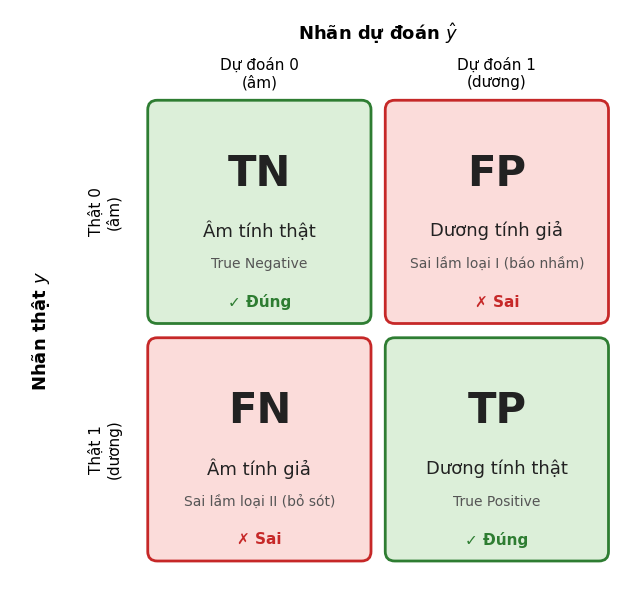

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 6))
gap = 0.03   # khoảng trống giữa các ô
for (row, col), (code, name, note, correct) in cells.items():
    s = style[correct]
    x, y = col, 1 - row
    ax.add_patch(FancyBboxPatch((x + gap, y + gap), 1 - 2 * gap, 1 - 2 * gap,
                                boxstyle='round,pad=0,rounding_size=0.04',
                                facecolor=s['face'], edgecolor=s['edge'], lw=2))
    ax.text(x + 0.5, y + 0.66, code, ha='center', va='center', fontsize=30, fontweight='bold', color='#222222')
    ax.text(x + 0.5, y + 0.42, name, ha='center', va='center', fontsize=13, color='#222222')
    ax.text(x + 0.5, y + 0.28, note, ha='center', va='center', fontsize=10, color='#555555')
    ax.text(x + 0.5, y + 0.12, s['tag'], ha='center', va='center', fontsize=11, fontweight='bold', color=s['edge'])

# Nhãn cột (dự đoán) phía trên, nhãn hàng (thật) bên trái
ax.text(1, 2.25, 'Nhãn dự đoán $\\hat{y}$', ha='center', va='center', fontsize=13, fontweight='bold')
for col, label in enumerate(['Dự đoán 0\n(âm)', 'Dự đoán 1\n(dương)']):
    ax.text(col + 0.5, 2.08, label, ha='center', va='center', fontsize=11)
ax.text(-0.42, 1, 'Nhãn thật $y$', ha='center', va='center', fontsize=13, fontweight='bold', rotation=90)
for row, label in enumerate(['Thật 0\n(âm)', 'Thật 1\n(dương)']):
    ax.text(-0.15, 1.5 - row, label, ha='center', va='center', fontsize=11, rotation=90)

ax.set_xlim(-0.55, 2.05); ax.set_ylim(-0.05, 2.35)
ax.set_aspect('equal'); ax.axis('off')
fig.tight_layout()
fig.savefig(IMAGES / 'confusion_matrix.png', dpi=150, bbox_inches='tight')